<a href="https://colab.research.google.com/github/noar1997/Text-classifier-colab/blob/main/classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Dataset loading and machine learning
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Text preprocessing
import nltk
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
import time
from pathlib import Path


# Download resources needed for English text preprocessing
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


print("All libraries imported successfully!")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All libraries imported successfully!


[nltk_data]   Package omw-1.4 is already up-to-date!


Data set overview
Training documents: 11314
Training labels: 11314
Testing documents: 7532
Testing labels: 7532
Number of categories: 20
Categories: ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Category distribution
alt.atheism: Train = 480, Test = 319
comp.graphics: Train = 584, Test = 389
comp.os.ms-windows.misc: Train = 591, Test = 394
comp.sys.ibm.pc.hardware: Train = 590, Test = 392
comp.sys.mac.hardware: Train = 578, Test = 385
comp.windows.x: Train = 593, Test = 395
misc.forsale: Train = 585, Test = 390
rec.autos: Train = 594, Test = 396
rec.motorcycles: Train = 598, Test = 398
rec.sport.baseball: Train = 597, Test = 397
rec.sport.hocke

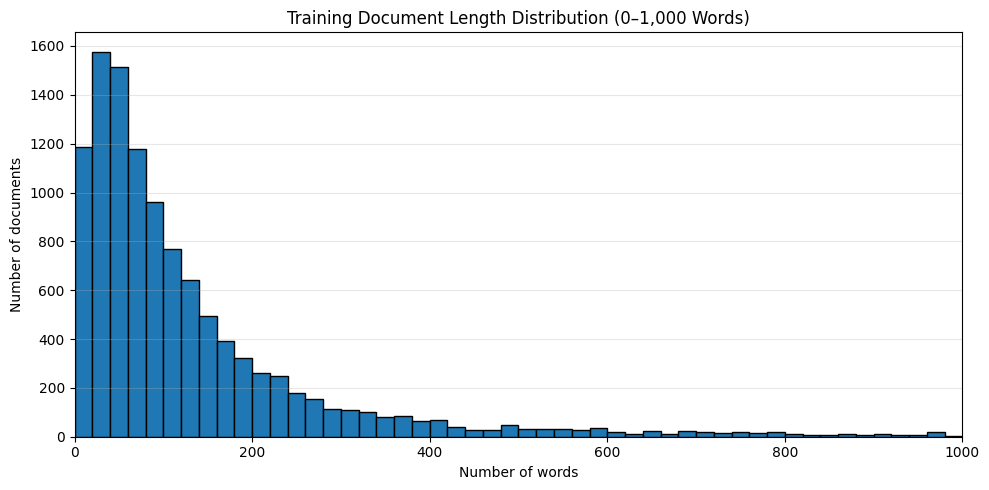

In [ ]:
#exploration of the dataset
train = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes")
)

test = fetch_20newsgroups(
    subset="test",
    remove=("headers", "footers", "quotes")
)

print("Data set overview")
print("Training documents:", len(train.data))
print("Training labels:", len(train.target))
print("Testing documents:", len(test.data))
print("Testing labels:", len(test.target))
print("Number of categories:", len(train.target_names))
print("Categories:", train.target_names)

# Check document-label consistency
assert len(train.data) == len(train.target)
assert len(test.data) == len(test.target)

# 3. Category distribution
print("Category distribution")

train_counts = pd.Series(train.target).value_counts().sort_index()
test_counts = pd.Series(test.target).value_counts().sort_index()

for i, category_name in enumerate(train.target_names):
    print(
        f"{category_name}: "
        f"Train = {train_counts.get(i, 0)}, "
        f"Test = {test_counts.get(i, 0)}"
    )
print("")
# 4. Inspect three representative documents
print("Sample documents")

for i in [0, 15, 99]:
    print(f"Document {i + 1}")
    print("Category:", train.target_names[train.target[i]])
    print(train.data[i][:300])

# 5. Data quality and document length statistics
print("Data quality and length")

empty_train = sum(1 for doc in train.data if not doc.strip())
empty_test = sum(1 for doc in test.data if not doc.strip())

print("Empty training documents:", empty_train)
print("Empty testing documents:", empty_test)

print("Unique training documents:", len(set(train.data)))
print("Unique testing documents:", len(set(test.data)))

word_counts = [len(doc.split()) for doc in train.data]

print("Shortest document (words):", min(word_counts))
print("Longest document (words):", max(word_counts))
print("Mean document length (words):", round(np.mean(word_counts), 2))
print("Median document length (words):", np.median(word_counts))

# 6. Document length distribution
plt.figure(figsize=(10, 5))

plt.hist(word_counts, bins=50, range=(0, 1000), edgecolor="black")
plt.xlim(0, 1000)
plt.xlabel("Number of words")
plt.ylabel("Number of documents")
plt.title("Training Document Length Distribution (0–1,000 Words)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
#pre processing
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))


def pre_processing(text):
  text_lower = text.lower()
  tokens = word_tokenize(text_lower)

  tokens_no_punctuations = [
      token for token in tokens
      if token.isalpha()
  ]

  tokens_no_stop_words = [
      token for token in tokens_no_punctuations
      if token not in stop_words
  ]

  lemmatized_tokens = [
    lemmatizer.lemmatize(token)
    for token in tokens_no_stop_words
]
  cleaned_text = " ".join(lemmatized_tokens)
  return cleaned_text

#pre process train data
processed_train_data = []

for text in train.data:
  result = pre_processing(text)
  processed_train_data.append(result)
#Pre process test data
processed_test_data = []
for text in test.data:
  result = pre_processing(text)
  processed_test_data.append(result)


print(processed_test_data[0])
print(processed_train_data[0])

little confused model bonnevilles heard le se lse sse ssei could someone tell difference far feature performance also curious know book value prefereably model much less book value usually get word much demand time year heard early summer best time buy
wondering anyone could enlighten car saw day sport car looked late early called bricklin door really small addition front bumper separate rest body know anyone tellme model name engine spec year production car made history whatever info funky looking car please


In [ ]:
#vectorize the data
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(processed_train_data)
X_test = vectorizer.transform(processed_test_data)

y_train = train.target
y_test = test.target

model = MultinomialNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

#model evaluation
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

report = classification_report(
    y_test,
    y_pred,
    target_names=train.target_names,
    output_dict=True,
    zero_division=0
)









Classification Report:
                          precision  recall  f1-score    support
alt.atheism                  0.5946  0.3448    0.4365   319.0000
comp.graphics                0.5862  0.6555    0.6189   389.0000
comp.os.ms-windows.misc      0.6667  0.0863    0.1528   394.0000
comp.sys.ibm.pc.hardware     0.5317  0.7066    0.6068   392.0000
comp.sys.mac.hardware        0.7053  0.5844    0.6392   385.0000
comp.windows.x               0.5651  0.7797    0.6553   395.0000
misc.forsale                 0.8728  0.6333    0.7340   390.0000
rec.autos                    0.8085  0.7247    0.7643   396.0000
rec.motorcycles              0.8858  0.6432    0.7453   398.0000
rec.sport.baseball           0.9434  0.7557    0.8392   397.0000
rec.sport.hockey             0.5827  0.9098    0.7104   399.0000
sci.crypt                    0.5468  0.7677    0.6387   396.0000
sci.electronics              0.6853  0.4987    0.5773   393.0000
sci.med                      0.8160  0.7727    0.7938   396.0000
sc

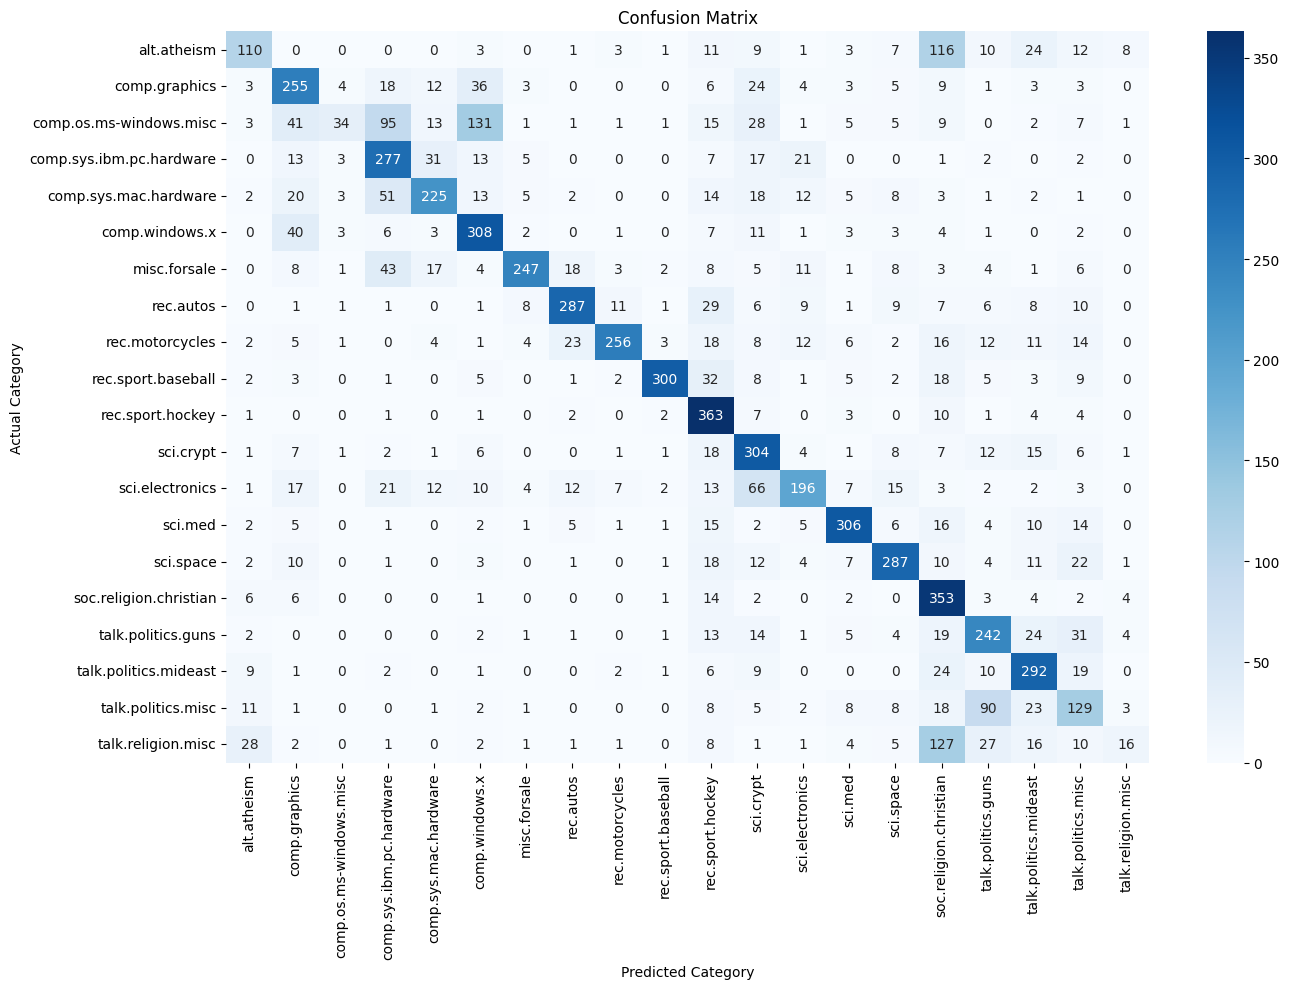



Accuracy:  0.6355549654806161
macro_f1 score : 0.6045810122795217



Categories with the most misclassifications:
               Category  Misclassified Documents
comp.os.ms-windows.misc                      360
     talk.religion.misc                      235
            alt.atheism                      209
        sci.electronics                      197
     talk.politics.misc                      181


In [ ]:
# Evaluating the model

# Calculate evaluation metrics first
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

# Generate the classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=train.target_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("Classification Report:")
print(report_df.round(4))

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print("")
print("")
#confussion matrix
labels = range(20)
cm = confusion_matrix(y_test, y_pred, labels=labels)
#print(cm)

#Best performing classes 8 and 10
#problematic class 2
#weak class 19
plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train.target_names,
    yticklabels=train.target_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
print("")
print("")
print("Accuracy: ", accuracy)
print("macro_f1 score :", macro_f1)
print("")
print("")
#missclasifications:
misclassified = cm.sum(axis=1) - cm.diagonal()

misclassification_df = pd.DataFrame({
    "Category": train.target_names,
    "Misclassified Documents": misclassified
})

print("\nCategories with the most misclassifications:")
print(
    misclassification_df
    .sort_values("Misclassified Documents", ascending=False)
    .head(5)
    .to_string(index=False)
)


   Training size (%)  Documents  Accuracy  F1-score
0               10.0       1131  0.415162  0.368966
1               30.0       3394  0.539697  0.506384
2               50.0       5657  0.576208  0.540983
3              100.0      11314  0.635555  0.604581


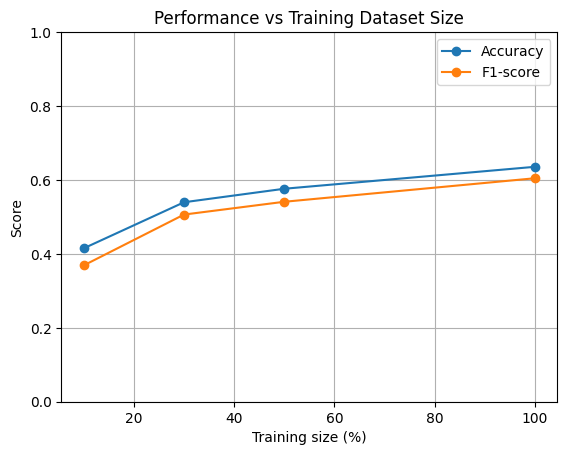

In [ ]:
percentages = [0.10, 0.30, 0.50, 1.0]
results = []

for percentage in percentages:

    # Select a subset of training documents
    if percentage < 1.0:
        X_subset, _, y_subset, _ = train_test_split(
            X_train,
            y_train,
            train_size=percentage,
            random_state=42,
            stratify=y_train
        )
    else:
        X_subset = X_train
        y_subset = y_train

    # Train the model
    model = MultinomialNB()
    model.fit(X_subset, y_subset)

    # Evaluate on the same test dataset
    y_pred = model.predict(X_test)

    # Save performance metrics
    results.append({
        "Training size (%)": percentage * 100,
        "Documents": X_subset.shape[0],
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1-score": f1_score(
            y_test, y_pred, average="macro"
        )
    })

# Display results
results_df = pd.DataFrame(results)
print(results_df)

results_df.plot(
    x="Training size (%)",
    y=["Accuracy", "F1-score"],
    marker="o"
)

plt.title("Performance vs Training Dataset Size")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True)
plt.show()


In [ ]:
model = MultinomialNB()
model.fit (X_train, y_train)

y_pred = model.predict(X_test)
print("Final accuracy:", accuracy_score(y_test, y_pred))
print("Final macro F1 score: ", f1_score(y_test, y_pred, average = "macro"))
test_examples = {
    "Space": """
    Astronomers discovered a new planet orbiting a distant star.
    The telescope collected data about its atmosphere.
    """,

    "Cars": """
    The new electric vehicle has a longer battery range
    and faster charging than the previous model.
    """,

    "Medicine": """
    Researchers conducted a clinical trial to evaluate
    a new treatment for patients with heart disease.
    """,

    "Computer graphics": """
    The graphics card renders three dimensional images
    using advanced shading and texture processing.
    """,

    "Politics": """
    Parliament debated a new law concerning taxes,
    public spending and government policy.
    """,

    "Baseball": """
    The pitcher struck out three batters in the final
    inning, helping the team win the championship.
    """,

    "Motorcycles": """
    The rider upgraded the motorcycle suspension
    and engine before the long-distance race.
    """,

    "Cryptography": """
    The encryption algorithm uses a public key
    to secure messages sent across the network.
    """,

    "Social media": """
    just bought a new laptop and it keeps crashing 😭
    anyone know how to fix this??
    """,

    "Academic text": """
    This study evaluates statistical methods for
    identifying patterns in large biomedical datasets.
    """
}

for text_type, text in test_examples.items():
    cleaned = pre_processing(text)
    vectorized = vectorizer.transform([cleaned])
    prediction = model.predict(vectorized)[0]

    print(
        f"{text_type:20} = "
        f"{train.target_names[prediction]}"
    )

Final accuracy: 0.6355549654806161
Final macro F1 score:  0.6045810122795217
Space                = sci.space
Cars                 = rec.autos
Medicine             = sci.med
Computer graphics    = comp.graphics
Politics             = talk.politics.misc
Baseball             = rec.sport.baseball
Motorcycles          = rec.motorcycles
Cryptography         = sci.crypt
Social media         = comp.sys.mac.hardware
Academic text        = sci.med



Genre: News
Text: NASA scientists reported new observations of a distant planet and its atmosphere.
Actual category: sci.space
Predicted category: sci.space
Correct: True

Genre: News
Text: The computer company announced a new processor designed to improve system performance.
Actual category: comp.sys.ibm.pc.hardware
Predicted category: sci.crypt
Correct: False

Genre: Academic
Text: This study investigates algorithms for image processing and computer vision.
Actual category: comp.graphics
Predicted category: comp.graphics
Correct: True

Genre: Academic
Text: Researchers analyze encryption protocols and methods for secure digital communication.
Actual category: sci.crypt
Predicted category: sci.crypt
Correct: True

Genre: Social Media
Text: My computer keeps crashing after the latest hardware upgrade. Any suggestions?
Actual category: comp.sys.ibm.pc.hardware
Predicted category: comp.sys.mac.hardware
Correct: False

Genre: Social Media
Text: Just watched a fascinating documentary abou

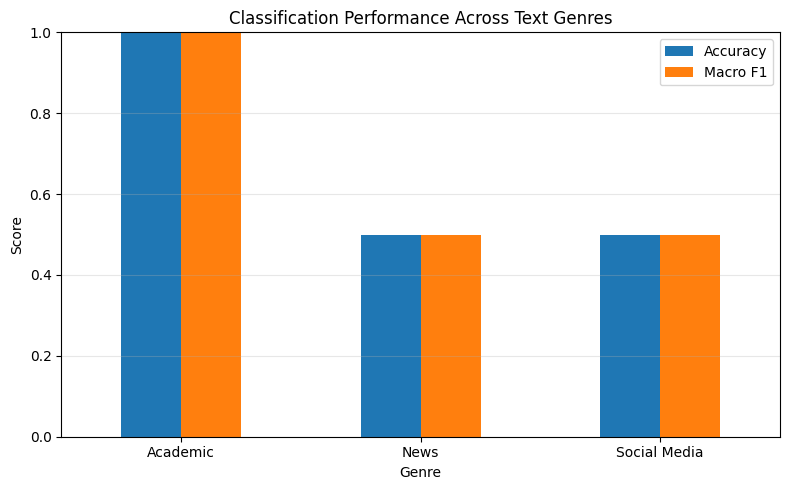

In [ ]:
# Cross-genre evaluation
# Run this after training your existing model and vectorizer.

genre_examples = [
    # News-style text
    {
        "genre": "News",
        "text": "NASA scientists reported new observations of a distant planet and its atmosphere.",
        "label": "sci.space"
    },
    {
        "genre": "News",
        "text": "The computer company announced a new processor designed to improve system performance.",
        "label": "comp.sys.ibm.pc.hardware"
    },

    # Academic-style text
    {
        "genre": "Academic",
        "text": "This study investigates algorithms for image processing and computer vision.",
        "label": "comp.graphics"
    },
    {
        "genre": "Academic",
        "text": "Researchers analyze encryption protocols and methods for secure digital communication.",
        "label": "sci.crypt"
    },

    # Social-media-style text
    {
        "genre": "Social Media",
        "text": "My computer keeps crashing after the latest hardware upgrade. Any suggestions?",
        "label": "comp.sys.ibm.pc.hardware"
    },
    {
        "genre": "Social Media",
        "text": "Just watched a fascinating documentary about space exploration and distant galaxies!",
        "label": "sci.space"
    }
]

# Prepare text and labels
genre_texts = [item["text"] for item in genre_examples]
genre_labels = [
    train.target_names.index(item["label"])
    for item in genre_examples
]
genre_names = [item["genre"] for item in genre_examples]

# Apply your existing preprocessing and vectorizer
cleaned_texts = [
    pre_processing(text) for text in genre_texts
]
X_genre = vectorizer.transform(cleaned_texts)

# Predict categories
genre_predictions = model.predict(X_genre)

# Display individual predictions
for i, item in enumerate(genre_examples):
    actual = train.target_names[genre_labels[i]]
    predicted = train.target_names[genre_predictions[i]]

    print(f"\nGenre: {genre_names[i]}")
    print(f"Text: {item['text']}")
    print(f"Actual category: {actual}")
    print(f"Predicted category: {predicted}")
    print(f"Correct: {actual == predicted}")

# Evaluate each genre separately
genre_results = []

for genre in sorted(set(genre_names)):
    indices = [
        i for i, name in enumerate(genre_names)
        if name == genre
    ]

    y_true = np.array(genre_labels)[indices]
    y_pred_genre = genre_predictions[indices]

    genre_results.append({
        "Genre": genre,
        "Documents": len(indices),
        "Accuracy": accuracy_score(y_true, y_pred_genre),
        "Macro F1": f1_score(
            y_true,
            y_pred_genre,
            labels=np.unique(y_true),
            average="macro",
            zero_division=0
        )
    })

genre_results_df = pd.DataFrame(genre_results)

print("\nCross-Genre Evaluation Results")
print(genre_results_df.round(3).to_string(index=False))

# Visualize the results
genre_results_df.set_index("Genre")[
    ["Accuracy", "Macro F1"]
].plot(kind="bar", figsize=(8, 5), ylim=(0, 1))

plt.title("Classification Performance Across Text Genres")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()